# 01 · ETL y limpieza de datos
**Proyecto final · Análisis de datos, BI y aprendizaje computacional**

## Problema de negocio
Una plataforma de suscripciones necesita saber **qué suscriptores no renovarán** al terminar su ciclo, para decidir a quién retener primero. Como el churn histórico ya es alto, el objetivo no es "marcar muchos casos", sino **ordenar a los usuarios por riesgo y por valor** con un modelo honesto, que se pueda usar en producción y que ayude a entender la situación.

## Fuentes (unidas por `usuario_id`)
| Fuente | Qué es | Para qué se usa |
|---|---|---|
| **KPI mensual** | Foto de los suscriptores **activos** cada mes (desde ene-2024). Si un usuario deja de estar activo no aparece ese mes; si renueva o se reactiva, vuelve a aparecer. | Comportamiento: uso de la plataforma, compras, cupones, contactos |
| **Órdenes de suscripción** | Un ciclo por orden: inicio, fin, producto, tipo de entrada y fecha de pago. | **Verdad sobre los ciclos**: si hubo renovación, cuándo y cómo se pagó |

`usuario_id` es un hash del correo con sal: los datos personales ya salieron anonimizados de la empresa y la sal no está en el repositorio.

## Definiciones del proyecto
- **Ciclo:** período de una orden de suscripción (`ciclo_inicio` → `ciclo_fin`).
- **Renovación:** el primer ciclo principal posterior del mismo usuario que empieza entre el vencimiento y 455 días después.
- **Churn a 90 días (`churn90`):** 1 si no hay renovación o si empieza más de 90 días después del vencimiento. Solo se calcula en ciclos **maduros** (vencimiento + 90 días ya ocurrió antes del corte, 31-oct-2026).
- **Ciclos principales vs. cortos:** los planes de ~92 días, de 14 días y los **regalos** no entran al modelo de churn; su paso a plan pagado se analiza aparte.
- **Ventana de predicción:** se predice a 4, 3, 2 y 1 mes del vencimiento, usando solo información anterior a esa fecha.

## Contenido
1. Extracción · 2. Diagnóstico · 3. Limpieza · 4. Ciclos y etiqueta · 5. Modelo en estrella · 6. Validaciones · 7. Primer vistazo · 8. Carga · 9. Conclusiones

In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RAIZ = Path("..").resolve()
sys.path.append(str(RAIZ))
from src import etl

RAW_KPI = RAIZ / "data" / "raw" / "dataset suscriptores.csv"
RAW_ORD = RAIZ / "data" / "raw" / "dataset suscriptores original.csv"
PROC = RAIZ / "data" / "processed"
pd.set_option("display.width", 200, "display.max_columns", 60)
sns.set_theme(style="whitegrid")

## 1. Extracción: lectura de las fuentes

In [2]:
kpi = etl.leer_kpi(RAW_KPI)
ord_ = etl.leer_ordenes(RAW_ORD)
print("KPI mensual:", kpi.shape, "| período", kpi["fecha"].min().date(), "→", kpi["fecha"].max().date(), "| usuarios", f"{kpi['usuario_id'].nunique():,}")
print("Órdenes    :", ord_.shape, "| usuarios", f"{ord_['usuario_id'].nunique():,}")
ord_.head(3)

KPI mensual: (735446, 42) | período 2024-01-31 → 2026-11-30 | usuarios 44,324
Órdenes    : (161890, 9) | usuarios 58,722


,usuario_id,ordenid,productoid,suscripcionestado,ordenestado,tipo_entrada,ciclo_inicio,ciclo_fin,fecha_pago
0,45ec8ff8116b2868,589452,91113,wc-expired,wc-completed,RENOVACION,2023-05-25,2024-05-18,2023-05-17
1,8cc6b24a169f5ab0,327308,237481,wc-expired,wc-completed,UPGRADE,2022-02-09,2023-02-09,2022-02-08
2,cdf2fd8afbe55e0b,587274,91113,wc-expired,wc-completed,UPGRADE,2023-05-18,2024-05-18,2023-05-17


## 2. Diagnóstico de calidad
Antes de limpiar se mide qué tan sucio está cada aspecto, para decidir con evidencia.

In [3]:
def diagnostico_kpi(d):
    ok = d["usuario_id"].astype(str).str.fullmatch(etl.ID_VALIDO)
    v = d["fecha_vencimiento_membresia"]
    imposible = v.notna() & ((v < etl.FECHA_MIN) | (v > etl.FECHA_MAX_VENC))
    return pd.Series({
        "KPI · filas con usuario_id dañado": int((~ok).sum()),
        "KPI · filas duplicadas exactas": int(d.duplicated().sum()),
        "KPI · vencimientos imposibles": int(imposible.sum()),
        "KPI · filas del mes parcial (nov-2026)": int((d["fecha"] > etl.CORTE).sum()),
        "KPI · usuario-mes repetidos (debería ser 0)": int(d.duplicated(["usuario_id", "fecha"]).sum()),
    })

def diagnostico_ord(o):
    return pd.Series({
        "Órdenes · no completadas": int((o["ordenestado"] != "wc-completed").sum()),
        "Órdenes · suscripción cancelada": int(o["suscripcionestado"].isin(etl.ESTADOS_CANCELADOS).sum()),
        "Órdenes · tipo de entrada ERROR": int((o["tipo_entrada"] == "ERROR").sum()),
        "Órdenes · fin anterior al inicio": int((o["ciclo_fin"] < o["ciclo_inicio"]).sum()),
        "Órdenes · fin posterior a 2030": int((o["ciclo_fin"] > etl.FECHA_MAX_VENC).sum()),
        "Órdenes · sin fecha de pago": int(o["fecha_pago"].isna().sum()),
        "Órdenes · usuario-orden repetido": int(o.duplicated(["usuario_id", "ordenid"]).sum()),
    })
pd.concat([diagnostico_kpi(kpi), diagnostico_ord(ord_)]).to_frame("cantidad")

,cantidad
KPI · filas con usuario_id dañado,502
KPI · filas duplicadas exactas,0
KPI · vencimientos imposibles,85
KPI · filas del mes parcial (nov-2026),16731
KPI · usuario-mes repetidos (debería ser 0),0
Órdenes · no completadas,43242
Órdenes · suscripción cancelada,42793
Órdenes · tipo de entrada ERROR,42
Órdenes · fin anterior al inicio,124
Órdenes · fin posterior a 2030,3


**Decisiones de limpieza** (documentadas para que el proceso sea reproducible):
1. **KPI · `usuario_id` dañado:** parte de los hash se guardó como número en notación científica (p. ej. `7,76027E+15`) y distintos usuarios quedaron con el mismo texto. No se recuperan: esas filas se **descartan** y se cuentan.
2. **KPI · vencimientos imposibles:** se convierten en nulos; la fila se conserva porque sus demás datos sirven.
3. **KPI · mes parcial:** se conserva con la marca `snapshot_parcial`.
4. **Órdenes · solo cuentan las órdenes completadas** y sin suscripción cancelada: una orden no pagada no es un ciclo.
5. **Órdenes · tipo `ERROR`, fechas invertidas, fin posterior a 2030 y órdenes duplicadas** se descartan.
6. **Ciclos solapados** (una renovación o un upgrade pagado antes del vencimiento) se **conservan**: es comportamiento real. La renovación se busca desde el vencimiento.
7. **Productos:** los principales (`91113`, `585066`, `237481`, `1091442`, `237480`) entran al modelo; los de ~92 días, 14 días y los regalos se marcan como "Corto u otro".

## 3. Transformación: limpieza

In [4]:
kpi_l, inf_kpi = etl.limpiar_kpi(kpi)
ord_l, inf_ord = etl.limpiar_ordenes(ord_)
pd.concat([pd.Series(inf_kpi, name="KPI"), pd.Series(inf_ord, name="Órdenes")], axis=1)

,KPI,Órdenes
filas_entrada,735446.0,161890.0
ids_danados_distintos,36.0,NaN
filas_id_danado,502.0,NaN
filas_duplicadas,0.0,NaN
vencimientos_imposibles,85.0,NaN
filas_sin_vencimiento,188.0,NaN
valores_negativos,0.0,NaN
filas_salida,734944.0,109793.0
descartadas_id_invalido,NaN,0.0
descartadas_orden_no_completada,NaN,43242.0


## 4. Ciclos y etiqueta de churn
Cada orden limpia es un ciclo. Para los ciclos principales se busca la renovación y se calcula `churn90`. La definición es explícita: un ciclo es churn si el usuario no inicia otro ciclo principal en los 90 días posteriores al fin del ciclo, y solo se etiquetan los ciclos **maduros** (cuya ventana de 90 días ya cerró).

In [5]:
ciclos = etl.construir_ciclos(ord_l)
maduros = ciclos[ciclos["madura"]]
print(f"Ciclos: {len(ciclos):,} | maduros (churn calculable): {len(maduros):,} | churn90 global: {maduros['churn90'].mean():.1%}")

por_anio = maduros.groupby(maduros["ciclo_fin"].dt.year)["churn90"].agg(["size", "mean"]).rename(columns={"size": "ciclos", "mean": "churn90"}).round(3)
print("Estabilidad de la etiqueta por año de vencimiento:"); display(por_anio)

Ciclos: 109,793 | maduros (churn calculable): 74,421 | churn90 global: 49.6%
Estabilidad de la etiqueta por año de vencimiento:


,ciclos,churn90
ciclo_fin,,
2023,21696,0.535
2024,19875,0.429
2025,21106,0.504
2026,11744,0.524


La etiqueta se construye **para todos los ciclos maduros**. Se verifica además con los controles de calidad de las secciones siguientes (ciclos sin solapes, cada ciclo con su orden, renovaciones posteriores al inicio).

## 5. Transformación: modelo de datos en estrella
Se separan los **hechos** (lo que se mide) de las **dimensiones** (por qué o por quién), para que Power BI y los modelos trabajen sobre tablas simples.

```
                    dim_fecha
                        │
dim_usuario ── fact_snapshot_mensual ── dim_categoria
     │
     └──── fact_ciclo ──── dim_producto
```

| Tabla | Grano | Contenido |
|---|---|---|
| `fact_snapshot_mensual` | un usuario en un mes | uso de la plataforma, compras, cupones, vencimiento |
| `fact_ciclo` | un ciclo (orden) | inicio, fin, producto, tipo de entrada, pago, renovación, **churn a 90 días** |
| `dim_usuario` | un usuario | meses activos, ciclos, reactivaciones, presencia en cada fuente |
| `fact_movimiento_mensual` | un mes | activos, nuevos, reactivados y bajas |
| `dim_producto` | un producto | grupo (principal / corto), duración mediana |
| `dim_categoria`, `dim_fecha` | categoría / mes | Básica, Oro, Platino · año, trimestre |

In [6]:
tablas = etl.construir_estrella(kpi_l, ciclos)
pd.DataFrame({"filas": {k: len(v) for k, v in tablas.items()}, "columnas": {k: v.shape[1] for k, v in tablas.items()}})

,filas,columnas
dim_usuario,56474,10
dim_categoria,3,2
dim_fecha,35,6
dim_producto,29,4
fact_ciclo,109793,19
fact_snapshot_mensual,734944,43
fact_movimiento_mensual,35,7


## 6. Validación de calidad

In [7]:
val = etl.validar(inf_kpi, inf_ord, tablas)
display(val)
assert val["cumple"].all(), "Hay controles de calidad que no se cumplen"
print("Todos los controles se cumplen")

,control,cumple,detalle
0,"KPI · llave (usuario_id, fecha) única",True,"734,944 filas"
1,KPI · usuario_id con formato válido,True,16 hex
2,KPI · sin nulos en llaves,True,
3,KPI · fechas dentro de ene-2024 a nov-2026,True,
4,KPI · cuadre de filas,True,"735,446 = 734,944 + 502 + 0"
5,Órdenes · cuadre de filas,True,"161,890 = 109,793 + 52,097"
6,Órdenes · ciclo_id único,True,"109,793 ciclos"
7,"Órdenes · (usuario, orden) único",True,
8,Órdenes · fin del ciclo no anterior al inicio,True,
9,churn90 solo en ciclos maduros de productos pr...,True,"74,421 maduros"


Todos los controles se cumplen


## 7. Primer vistazo al resultado
El análisis completo se hace en el notebook 02. Aquí se comprueba que las definiciones producen algo coherente.

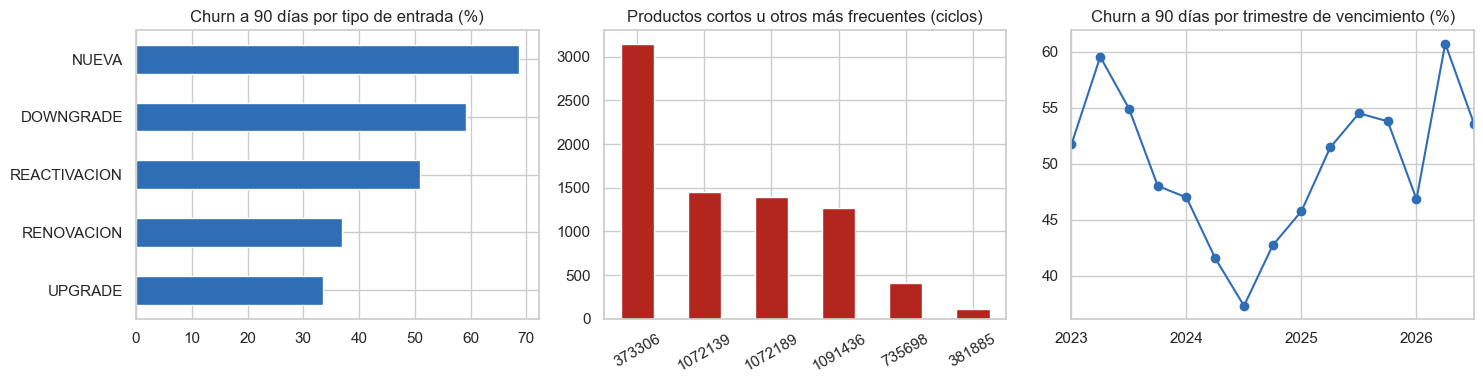

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
(maduros.groupby("tipo_entrada")["churn90"].mean().drop("SIN_DATO", errors="ignore").sort_values() * 100).plot.barh(ax=ax[0], color="#2F6DB5")
ax[0].set_title("Churn a 90 días por tipo de entrada (%)"); ax[0].set_ylabel("")
corto = ciclos[ciclos["grupo_producto"] != "Principal"]["productoid"].value_counts().head(6)
corto.plot.bar(ax=ax[1], color="#B3261E"); ax[1].set_title("Productos cortos u otros más frecuentes (ciclos)"); ax[1].tick_params(axis="x", rotation=30); ax[1].set_xlabel("")
(ciclos[ciclos["madura"]].groupby(ciclos["ciclo_fin"].dt.to_period("Q"))["churn90"].mean() * 100).plot(ax=ax[2], marker="o", color="#2F6DB5")
ax[2].set_title("Churn a 90 días por trimestre de vencimiento (%)"); ax[2].set_xlabel("")
plt.tight_layout(); plt.show()

## 8. Carga: guardar las tablas procesadas

In [9]:
etl.guardar(tablas, PROC)
for p in sorted(PROC.glob("*.csv")):
    print(f"{p.name:<28} {p.stat().st_size / 1e6:8.1f} MB")

dim_categoria.csv                 0.0 MB
dim_fecha.csv                     0.0 MB
dim_producto.csv                  0.0 MB
dim_usuario.csv                   4.2 MB
fact_ciclo.csv                   15.8 MB
fact_cohorte.csv                  0.0 MB
fact_monitoreo_modelo.csv         0.0 MB
fact_movimiento_mensual.csv       0.0 MB
fact_riesgo_ciclo.csv             2.0 MB
fact_snapshot_mensual.csv       104.9 MB


## 9. Conclusiones de la etapa
- Se integraron **dos fuentes** por un identificador anonimizado: el KPI mensual (comportamiento) y las órdenes (ciclos y renovaciones). El 99 % de los usuarios del KPI tiene órdenes.
- La etiqueta `churn90` se calcula para todos los ciclos maduros con una definición explícita y verificada con controles de calidad.
- Los regalos y planes cortos se separan del modelo de churn: tienen otra dinámica y se analizan aparte.
- El tipo de entrada ya anticipa grandes diferencias de churn (las altas nuevas casi duplican a las renovaciones), por lo que el modelo debe demostrar que aporta **más allá de ese contexto**.
- Las tablas quedan en `data/processed/` (no se suben al repositorio) y alimentan el EDA, el dashboard y el modelado.